Assessment: Breast Cancer Classification:

Your analysis should include the following parts:
    1 Create a breast cancer type classification model
    2 Explain which rules and patterns in the data your model captures
    3 Estimate the performance of your model on unseen data
    4 List the top 5 most important predictors
    5 Discuss how confident you are about these results (and why, or why not)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import arff
from sklearn.svm import SVC
from sklearn import datasets
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
%matplotlib inline


seed = 7


In [12]:
# load dataset and turn it to a dataframe

data, meta = arff.loadarff('data/BreastCancerAll-Reduced-WithMissingValues.arff')
df = pd.DataFrame(data)


In [13]:
#data cleaning

df.isnull().sum()
df[df.isnull().any(axis=1)]
df.shape

#remove rows with to many null values
df_removed_null_values = df.drop([131, 145], axis=0)


In [14]:

# data preprocessing

X = df_removed_null_values.drop("class", axis=1)
y = df_removed_null_values.iloc[:, -1]

y_transform = LabelEncoder().fit_transform(y)
X_train, X_test, y_train, y_test = train_test_split(X, y_transform, test_size=0.2, random_state=42)



In [15]:

# training Svc model
clf_rbf = SVC(random_state=seed, kernel='rbf').fit(X_train, y_train)
clf_linear = SVC(random_state=seed, kernel='linear').fit(X_train, y_train)


# model scores rbf
print("Training set score SVM_rbf: {:.3f}".format(clf_rbf.score(X_train, y_train)))
print("Test set score SVM_rbf: {:.3f}".format(clf_rbf.score(X_test, y_test)))
print("")

# model scores linear
print("Training set score SVM_linear: {:.3f}".format(clf_linear.score(X_train, y_train)))
print("Test set score SVM_linear: {:.3f}".format(clf_linear.score(X_test, y_test)))


Training set score SVM_rbf: 0.960
Test set score SVM_rbf: 0.806

Training set score SVM_linear: 0.968
Test set score SVM_linear: 0.774


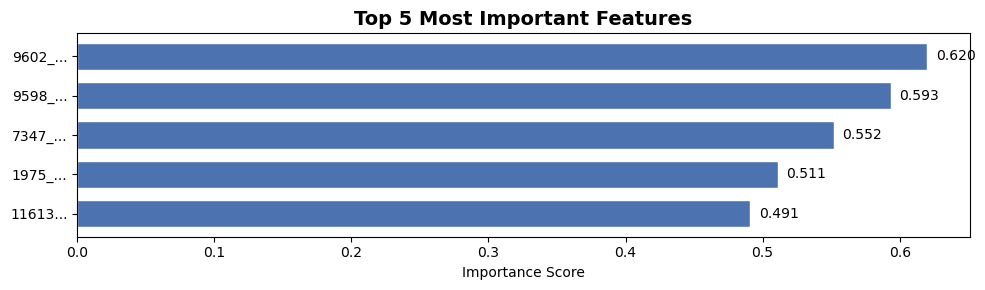

In [16]:
# most important features

if clf_linear.coef_.ndim > 1:
    importance = np.abs(clf_linear.coef_).mean(axis=0)
else:
    importance = np.abs(clf_linear.coef_[0])


feature_names = df.columns
top_n = 5
top_indices = np.argsort(importance)[-top_n:][::-1]
original_names = [feature_names[i] for i in top_indices]
short_names = [name[:5] + "..." if len(name) > 5 else name for name in original_names]

plt.figure(figsize=(10, 3))
y_pos = np.arange(top_n)
bars = plt.barh(y_pos, importance[top_indices], color='#4c72b0', edgecolor='white', height=0.7)
plt.yticks(y_pos, short_names)
plt.xlabel('Importance Score')
plt.title(f'Top {top_n} Most Important Features', fontsize=14, fontweight='bold')


for i, (idx, val) in enumerate(zip(top_indices, importance[top_indices])):
    offset = 0.01 * max(importance) if max(importance) > 0 else 0.1
    plt.text(val + offset, i, f'{val:.3f}', va='center', fontsize=10)

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

<Figure size 2000x1200 with 0 Axes>

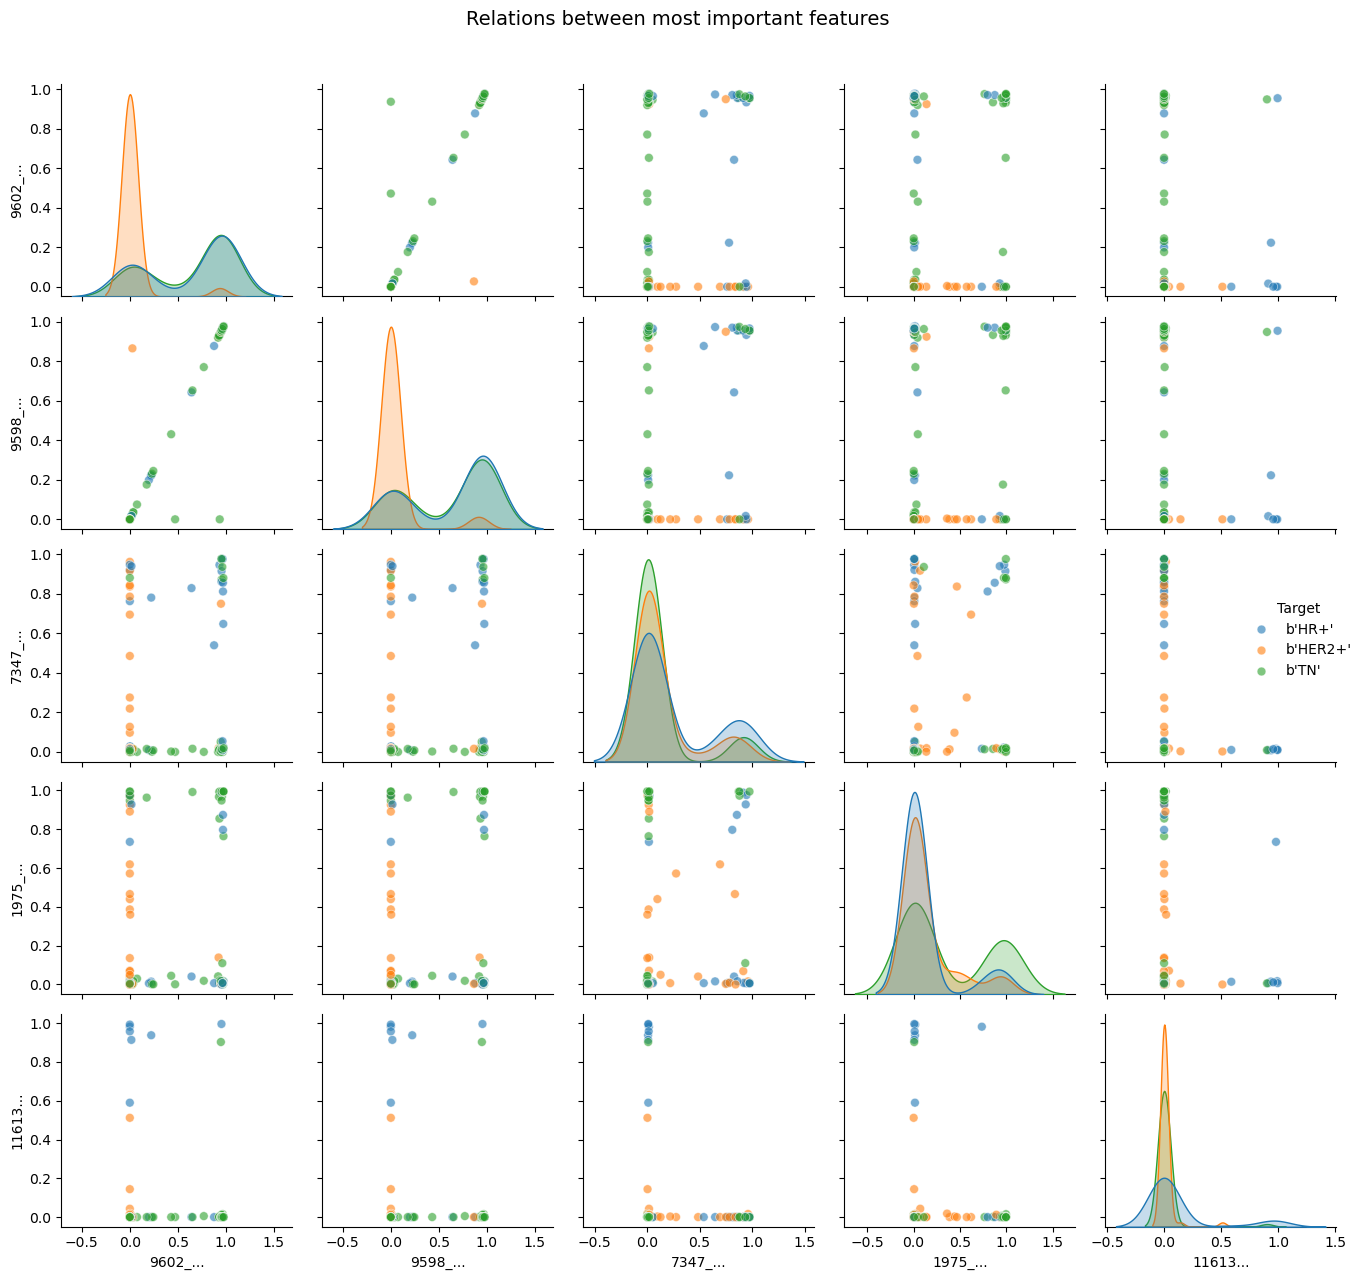

In [17]:
#pair plots

top_5_names_full = [feature_names[i] for i in top_indices]
top_5_names_short = [name[:5] + "..." if len(name) > 5 else name for name in top_5_names_full]
rename_map = dict(zip(top_5_names_full, top_5_names_short))
df_top5 = df[top_5_names_full].copy()
df_top5.rename(columns=rename_map, inplace=True)
df_top5['Target'] = df.iloc[:, -1]

plt.figure(figsize=(20, 12))

sns.pairplot(
    df_top5, 
    hue='Target', 
    diag_kind='kde', 
    plot_kws={'alpha': 0.6, 's': 40, 'edgecolor': 'w', 'linewidth': 0.5},
    diag_kws={'fill': True}
)

plt.suptitle('Relations between most important features', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()


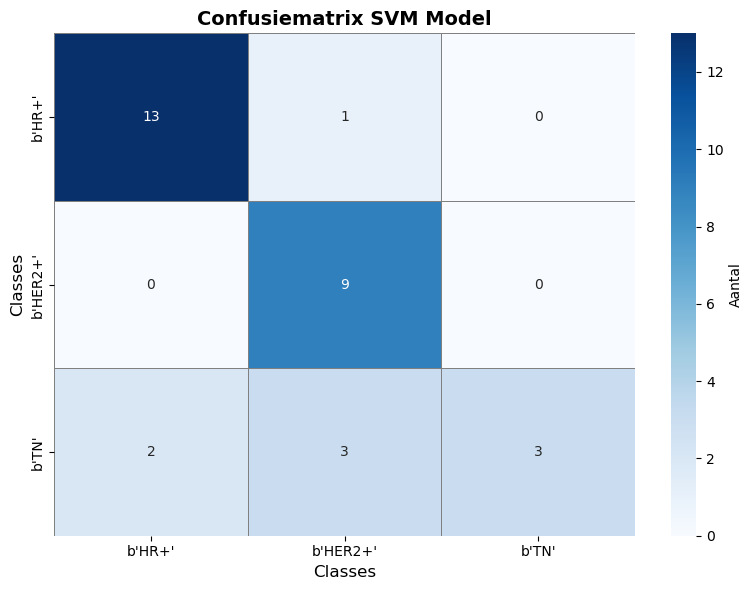


Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.93      0.90        14
           1       0.69      1.00      0.82         9
           2       1.00      0.38      0.55         8

    accuracy                           0.81        31
   macro avg       0.85      0.77      0.75        31
weighted avg       0.85      0.81      0.78        31



In [18]:
# confusion_matrix

y_pred = clf_rbf.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

class_names = y.unique()

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            linewidths=.5, linecolor='gray', cbar_kws={'label': 'Aantal'},
            xticklabels=class_names, yticklabels=class_names
            )
plt.xlabel('Classes', fontsize=12)
plt.ylabel('Classes', fontsize=12)
plt.title('Confusiematrix SVM Model', fontsize=14, fontweight='bold')


xticklabels=class_names,  # Echte namen op X-as
   # Echte namen op Y-as

plt.tight_layout()
plt.show()

# Optioneel: Print ook de tekstuele rapportage (Precision, Recall, F1-score)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))